# v3 - 3. Train, tune and cross-validate
Seven models: the Random-Forest family of the proposal (`call_only`, `message_only`, `combined_early`, `combined_stacked`) and the same three versions with an added word-level text model per channel (`*_text`). Each of the three Random-Forest versions is tuned with the same grid; cross-validation is **leave-one-fold-out over 4 family-safe folds** on the development buckets. Test buckets: never loaded.

In [1]:
import os, sys
from pathlib import Path
os.environ["TOADWATCH_VERSION"] = "v3"          # selects the strict "true accuracy" study (v3); keep this line first
sys.path.insert(0, str(Path.cwd().parent))       # notebooks live in ToadWatch_PR/notebooks
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from IPython.display import display
pd.set_option("display.width", 190); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 120)
from toadwatch import config as C, workflow_v3 as W, protocol_v3 as P, charts_v3 as CH, reporting as R
print("version:", C.VERSION, "| seed:", C.SEED, "| outputs:", C.OUTPUTS_DIR)

version: v3 | seed: 2028 | outputs: /home/rush/Downloads/Fase/ToadWatch_PR/outputs/v3


In [2]:
t = W.load_cv_results() if C.FINAL_TEST_LOCK.exists() else W.tune_and_cv()      # ~10 minutes (settings freeze after the final test)
t['summary'][['accuracy_mean', 'accuracy_std', 'f1_mean', 'balanced_accuracy_mean', 'hard_accuracy_mean', 'public_accuracy_mean']].round(4)

,accuracy_mean,accuracy_std,f1_mean,balanced_accuracy_mean,hard_accuracy_mean,public_accuracy_mean
variant,,,,,,
call_only,0.7994,0.0046,0.7812,0.8161,0.6231,0.8264
message_only,0.7308,0.0107,0.6936,0.7365,0.6703,0.7396
combined_early,0.8655,0.0063,0.8377,0.8666,0.7104,0.8886
combined_stacked,0.8716,0.0137,0.8450,0.8731,0.7078,0.8960
call_only_text,0.8143,0.0092,0.7902,0.8252,0.6509,0.8395
message_only_text,0.7704,0.0158,0.7328,0.7738,0.7053,0.7803
combined_text,0.9023,0.0060,0.8764,0.8968,0.7047,0.9324


### Read this table
* **hard_accuracy** = content-only accuracy (style-matched regime): this is the honest one.
* **public_accuracy** = optimistic (a source's style reveals its class).
* Compare with the ceilings below: a one-channel model can't honestly exceed ~85 %.

In [3]:
print(t['config']['ceilings'])
t['summary'][[c for c in t['summary'].columns if c.startswith('acc_') and c.endswith('_mean')]].round(3)

{'majority_class': 0.6010498687664042, 'call_oracle': 0.8489355497229513, 'message_oracle': 0.8489355497229513, 'both_channels_oracle': 1.0}


,acc_FF_mean,acc_FS_mean,acc_SF_mean,acc_SS_mean
variant,,,,
call_only,0.899,0.090,0.956,0.946
message_only,0.765,0.875,0.228,0.867
combined_early,0.872,0.627,0.863,0.979
combined_stacked,0.881,0.633,0.867,0.982
call_only_text,0.879,0.129,0.988,0.987
message_only_text,0.791,0.940,0.172,0.960
combined_text,0.869,0.756,0.944,0.999


/home/rush/Downloads/Fase/ToadWatch_PR/toadwatch/reporting.py:96: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=folds, x="variant", y=metric, order=order, palette=[_color(v) for v in order], ax=ax, width=0.5)


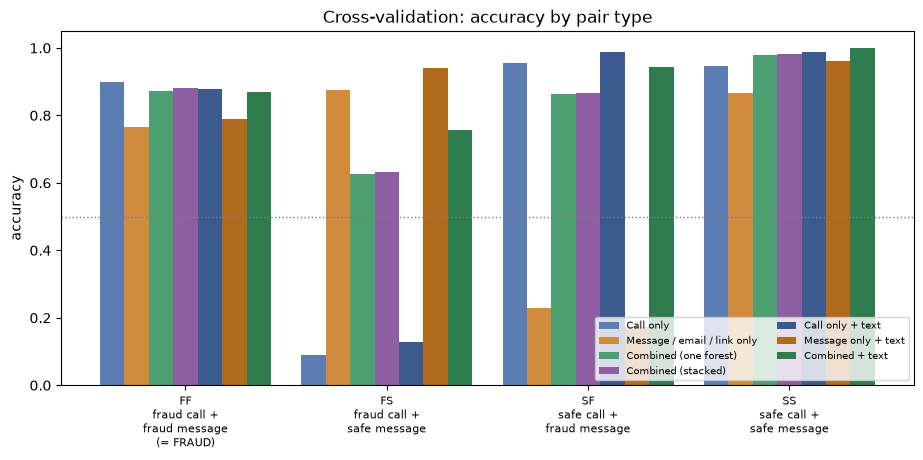

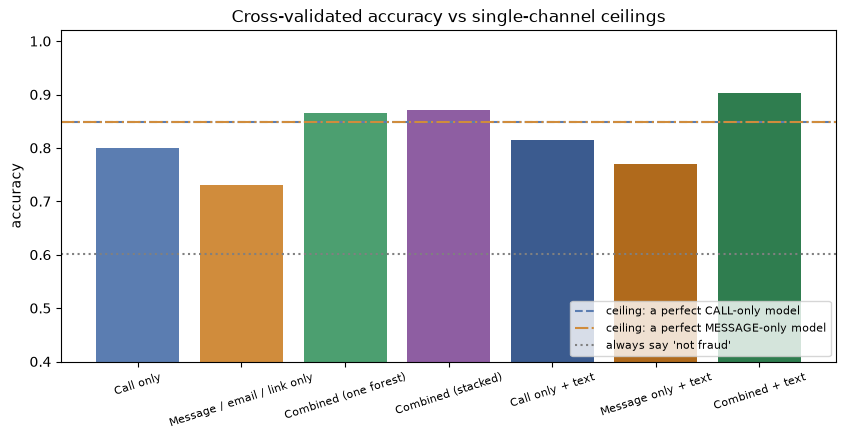

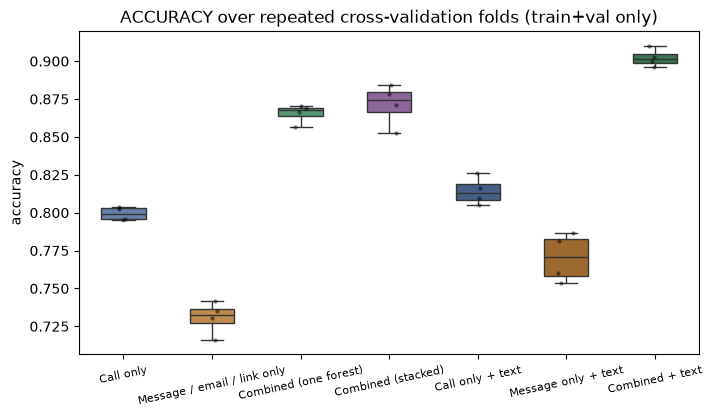

In [4]:
CH.plot_pair_type_accuracy(t['summary'].rename(columns=lambda c: c.replace('_mean', '')), 'Cross-validation: accuracy by pair type', 'v3_01_cv_accuracy_by_pair_type')
CH.plot_accuracy_vs_ceilings(t['summary'], t['config']['ceilings'], 'Cross-validated accuracy vs single-channel ceilings', 'v3_02_cv_accuracy_vs_ceilings')
R.plot_cv_scores(t['folds'], 'accuracy', 'v3_03_cv_accuracy_boxplot'); plt.show()

In [5]:
for v, g in t['grids'].items():
    print(v, '- best settings and CV F1:'); display(g.head(3).round(4))
print('Hard-record training weight, chosen by CV (1.0 = no extra weight):'); display(t['hard_weight_table'].round(4))

call_only - best settings and CV F1:


,n_estimators,max_depth,min_samples_leaf,max_features,cv_f1_mean,cv_f1_std
0,300,12.0,3,sqrt,0.7812,0.0085
1,300,NaN,3,sqrt,0.7777,0.0064
2,300,12.0,1,sqrt,0.7772,0.0070


message_only - best settings and CV F1:


,n_estimators,max_depth,min_samples_leaf,max_features,cv_f1_mean,cv_f1_std
0,300,12.0,3,sqrt,0.6936,0.0149
1,300,NaN,3,sqrt,0.6906,0.0187
2,300,12.0,3,0.5,0.6885,0.0211


combined_early - best settings and CV F1:


,n_estimators,max_depth,min_samples_leaf,max_features,cv_f1_mean,cv_f1_std
0,300,12.0,3,sqrt,0.8377,0.0107
1,300,NaN,1,sqrt,0.8361,0.0160
2,300,12.0,1,sqrt,0.8360,0.0162


Hard-record training weight, chosen by CV (1.0 = no extra weight):


,hard_weight,hard_balanced_accuracy,hard_accuracy,public_accuracy,overall_accuracy
0,1,0.6522,0.6679,0.8182,0.7986
1,4,0.6438,0.6548,0.8132,0.7923
2,10,0.6322,0.6453,0.8046,0.7839
3,30,0.6417,0.6536,0.7862,0.7689
